<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 20640  Columns: 10
Missing values per column (only columns with missing data):
total_bedrooms    207 

Train size: 16512  Test size: 4128 

Features used: 16

Test results (price in dollars):
  MAE  = 50,525
  RMSE = 70,892
  R2   = 0.6266
  (Just guessing the average price gives MAE = 91,364)
Train R2 = 0.6550

Top 6 features (weights on standardized inputs):
  median_income                +74,290
  latitude                     -57,257
  longitude                    -56,007
  population                   -50,502
  households                   +49,044
  housing_median_age           +13,305

Actual vs Predicted (first 6 test blocks):
  Actual =    58,800   Predicted =    87,649
  Actual =   165,800   Predicted =   168,761
  Actual =   139,400   Predicted =   194,442
  Actual =   107,500   Predicted =   137,284
  Actual =   107,200   Predicted =    69,225
  Actual =   353,300   Predicted =   305,856

New block: median income 5.0, 30 years old, 2000 rooms, 350 households, NEAR BAY
P

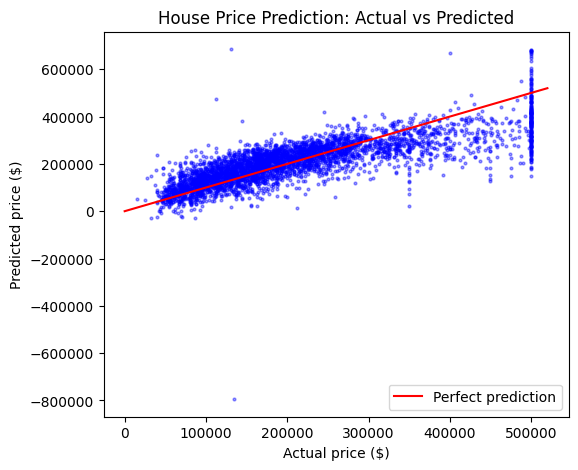

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset: California Housing (1990 census) - program14.csv, used as it is
# median_house_value = price of houses in a block (in US dollars)

# ---- 1. Load CSV ----
df = pd.read_csv('program14.csv')
print("Rows:", len(df), " Columns:", df.shape[1])
print("Missing values per column (only columns with missing data):")
print(df.isna().sum()[df.isna().sum() > 0].to_string(), "\n")

# ---- 2. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(df))
split = int(0.8 * len(df))
train, test = df.iloc[idx[:split]].copy(), df.iloc[idx[split:]].copy()
print("Train size:", len(train), " Test size:", len(test), "\n")

# ---- 3. Fill missing values with the training median ----
median_bedrooms = train['total_bedrooms'].median()
train['total_bedrooms'] = train['total_bedrooms'].fillna(median_bedrooms)
test['total_bedrooms'] = test['total_bedrooms'].fillna(median_bedrooms)

# ---- 4. Prepare features ----
def prepare(data):
    d = data.copy()
    d['rooms_per_household'] = d['total_rooms'] / d['households']
    d['bedrooms_per_room'] = d['total_bedrooms'] / d['total_rooms']
    d['population_per_household'] = d['population'] / d['households']
    d = d.drop(columns='median_house_value')
    d = pd.get_dummies(d, columns=['ocean_proximity'], dtype=float)   # text -> 0/1 columns
    return d

Xtr_df, Xte_df = prepare(train), prepare(test)
Xte_df = Xte_df.reindex(columns=Xtr_df.columns, fill_value=0.0)
ytr, yte = train['median_house_value'].values, test['median_house_value'].values
print("Features used:", Xtr_df.shape[1])
Xtr, Xte = Xtr_df.values.astype(float), Xte_df.values.astype(float)

# ---- 5. Standardize inputs (using training mean and std) ----
mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
sd[sd == 0] = 1
Xtr_s, Xte_s = (Xtr - mu) / sd, (Xte - mu) / sd

# ---- 6. Train Multiple Linear Regression (least squares) ----
A = np.column_stack([np.ones(len(Xtr_s)), Xtr_s])       # column of 1s = intercept
w = np.linalg.lstsq(A, ytr, rcond=None)[0]

def predict(Xs):
    return np.column_stack([np.ones(len(Xs)), Xs]) @ w

# ---- 7. Evaluate ----
def metrics(actual, predicted):
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    r2 = 1 - np.sum((actual - predicted) ** 2) / np.sum((actual - actual.mean()) ** 2)
    return mae, rmse, r2

pred_te = predict(Xte_s)
mae, rmse, r2 = metrics(yte, pred_te)
print("\nTest results (price in dollars):")
print(f"  MAE  = {mae:,.0f}")
print(f"  RMSE = {rmse:,.0f}")
print(f"  R2   = {r2:.4f}")
print(f"  (Just guessing the average price gives MAE = {np.mean(np.abs(yte - ytr.mean())):,.0f})")
print(f"Train R2 = {metrics(ytr, predict(Xtr_s))[2]:.4f}\n")

# ---- 8. Which features matter most ----
print("Top 6 features (weights on standardized inputs):")
for name, wt in sorted(zip(Xtr_df.columns, w[1:]), key=lambda t: -abs(t[1]))[:6]:
    print(f"  {name:<28} {wt:+,.0f}")

# ---- 9. Actual vs predicted ----
print("\nActual vs Predicted (first 6 test blocks):")
for a, p in zip(yte[:6], pred_te[:6]):
    print(f"  Actual = {a:9,.0f}   Predicted = {p:9,.0f}")

# ---- 10. Predict price for a new house block ----
new = pd.DataFrame([{'longitude': -122.25, 'latitude': 37.85, 'housing_median_age': 30,
                     'total_rooms': 2000, 'total_bedrooms': 400, 'population': 900,
                     'households': 350, 'median_income': 5.0, 'median_house_value': 0,
                     'ocean_proximity': 'NEAR BAY'}])
new_df = prepare(new).reindex(columns=Xtr_df.columns, fill_value=0.0)
price = predict((new_df.values.astype(float) - mu) / sd)[0]
print("\nNew block: median income 5.0, 30 years old, 2000 rooms, 350 households, NEAR BAY")
print(f"Predicted median house value: ${price:,.0f}")

# ---- 11. Plot ----
plt.figure(figsize=(6, 5))
plt.scatter(yte, pred_te, s=4, alpha=0.4, color='blue')
lim = [0, 520000]
plt.plot(lim, lim, color='red', label='Perfect prediction')
plt.xlabel('Actual price ($)')
plt.ylabel('Predicted price ($)')
plt.title('House Price Prediction: Actual vs Predicted')
plt.legend()
plt.show()